Human oversight Agentic Systems that requires Approval before execution

In [18]:
from langchain_openai import ChatOpenAI
from langchain_tavily import TavilySearch
from langchain_core.tools import Tool
from langgraph.graph import StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

from typing import Annotated
from typing_extensions import TypedDict

from dotenv import load_dotenv
_ = load_dotenv()

In [19]:
# Defining the model for the chatbot agent
llm = ChatOpenAI(
    model="llama3.2:3b",
    base_url="http://127.0.0.1:11434/v1",
    api_key="ollama",
)
# defining the search tool
tavily_search = TavilySearch(max_results=10)

# list of the tools for agent
tools = [tavily_search]

# binding the tools for llm
llm_with_tools = llm.bind_tools(tools)

# Defining the state graph for the agent
class State(TypedDict):
    messages: Annotated[list, add_messages]
graphbuilder = StateGraph(State)

# defining the nodes
def chatbot(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}
graphbuilder.add_node("chatbot", chatbot)
tool_node = ToolNode(tools=tools)
graphbuilder.add_node("tools", tool_node)

# defining the edges
graphbuilder.add_conditional_edges("chatbot", tools_condition)
graphbuilder.add_edge("tools", "chatbot")
graphbuilder.set_entry_point("chatbot")

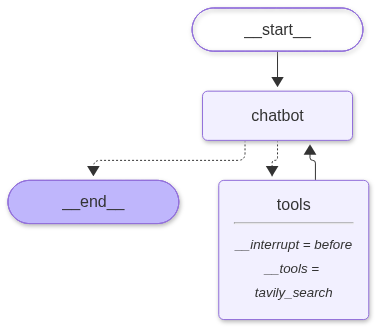

In [20]:
from langgraph.checkpoint.memory import MemorySaver
from IPython.display import display, Image

memory = MemorySaver()
graph = graphbuilder.compile(
    checkpointer=memory,
    interrupt_before=["tools"],
)
# Visualizing the graph
display(Image(graph.get_graph().draw_mermaid_png()))

In [21]:
user_input = "What is the weather in Tokyo?"
config = {"configurable": {"thread_id": "1"}}
# The configuration for the thread ID is set above
events = graph.stream(
    {"messages": [("user", user_input)]}, config, stream_mode="values"
)
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

What is the weather in Tokyo?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_94ym864q)
 Call ID: call_94ym864q
  Args:
    topic: general
    query: Tokyo weather
    include_domains: ["nasa.gov"]
    include_images: true
    start_date: null
    end_date: null
    search_depth: advanced
    time_range: null


In [22]:
snapshot = graph.get_state(config)
print(snapshot.next)

('tools',)


In [23]:
last_messages = snapshot.values["messages"][-1]
print(last_messages.tool_calls)

[{'name': 'tavily_search', 'args': {'topic': 'general', 'query': 'Tokyo weather', 'include_domains': '["nasa.gov"]', 'include_images': 'true', 'start_date': 'null', 'end_date': 'null', 'search_depth': 'advanced', 'time_range': 'null'}, 'id': 'call_94ym864q', 'type': 'tool_call'}]


In [24]:
events = graph.stream(None, config, stream_mode="values")
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_94ym864q)
 Call ID: call_94ym864q
  Args:
    topic: general
    query: Tokyo weather
    include_domains: ["nasa.gov"]
    include_images: true
    start_date: null
    end_date: null
    search_depth: advanced
    time_range: null
================================= Tool Message =================================
Name: tavily_search

Error invoking tool 'tavily_search' with kwargs {'topic': 'general', 'query': 'Tokyo weather', 'include_domains': '["nasa.gov"]', 'include_images': 'true', 'start_date': 'null', 'end_date': 'null', 'search_depth': 'advanced', 'time_range': 'null'} with error:
 include_domains: Input should be a valid list
time_range: Input should be 'day', 'week', 'month' or 'year'
 Please fix the error and try again.
================================== Ai Message ==================================

Unfortunately, I was unable to find any current weather informa

In [25]:
last_messages = snapshot.values["messages"][-1]
print("Original Tool Call:", last_messages.tool_calls)
print("Original Tool Call Details:", last_messages.id)

Original Tool Call: [{'name': 'tavily_search', 'args': {'topic': 'general', 'query': 'Tokyo weather', 'include_domains': '["nasa.gov"]', 'include_images': 'true', 'start_date': 'null', 'end_date': 'null', 'search_depth': 'advanced', 'time_range': 'null'}, 'id': 'call_94ym864q', 'type': 'tool_call'}]
Original Tool Call Details: lc_run--01a1f2f7-5583-7f23-80c1-68c3c9db3889-0


In [32]:
from langchain_core.messages import HumanMessage

singapore_question = "According to Population in Brief 2023, what was Singapore's total population as at June 2023?"
original_question = next(msg for msg in reversed(snapshot.values["messages"]) if isinstance(msg, HumanMessage))
updated_question = original_question.model_copy(update={"content": singapore_question})
new_tool_call = {
    **last_messages.tool_calls[0],
    "args": {"query": singapore_question, "include_domains": ["population.gov.sg"]},
}
new_ai_message = last_messages.model_copy(update={"content": "", "tool_calls": [new_tool_call]})
print("New tool call:", new_tool_call)

New tool call: {'name': 'tavily_search', 'args': {'query': "According to Population in Brief 2023, what was Singapore's total population as at June 2023?", 'include_domains': ['population.gov.sg']}, 'id': 'call_94ym864q', 'type': 'tool_call'}


In [33]:
singapore_config = graph.update_state(
    snapshot.config,
    {"messages": [updated_question, new_ai_message]},
    as_node="chatbot",
)
print("Next node:", graph.get_state(singapore_config).next)

Next node: ('tools',)


In [34]:
events = graph.stream(None, singapore_config, stream_mode="values")
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_94ym864q)
 Call ID: call_94ym864q
  Args:
    query: According to Population in Brief 2023, what was Singapore's total population as at June 2023?
    include_domains: ['population.gov.sg']
================================= Tool Message =================================
Name: tavily_search

{"query": "According to Population in Brief 2023, what was Singapore's total population as at June 2023?", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.population.gov.sg/media-centre/population-in-brief-2023-key-trends", "title": "Population in Brief 2023: Key Trends | National Population and Talent Division", "content": "Overall, Singapore’s total population stood at 5.92 million as at June 2023, a 5.0% increase from June 2022. Taking into account the decline in total population in 2020 and 2021 amidst the COVID-19 pandemic, the average to